In [58]:
import uproot
import awkward as ak
import numpy as np
import glob
import matplotlib.pyplot as plt

# plt.style.use('ggplot')

In [59]:
base = "/Users/PITLab/3D_sensors/Processed_data/"
fields = [
    'i_evt',
    'channel',
    'time',
    'baseline',
    'baseline_RMS',
    'noise',
    'amp',
    't_peak',
    'integral',
    # 'intfull',
    'risetime',
    'decaytime',
    # 'LP2_5',
    # 'LP2_10',
    # 'LP2_15',
    # 'LP2_20',
    # 'LP2_25',
    # 'LP2_30',
    # 'LP2_35',
    # 'LP2_40',
    # 'LP2_45',
    'LP2_50',
    # 'LP2_55',
    # 'LP2_60',
    # 'LP2_65',
    # 'LP2_70',
    # 'LP2_75',
    # 'LP2_80',
    # 'LP2_85',
    # 'LP2_90',
    # 'LP2_95',
    # 'LP2_100',
    # 'LP2_10mV',
    # 'LP2_20mV',
    # 'LP2_30mV',
    # 'LP2_50mV',
    # 'LP2_70mV',
    # 'LP2_90mV',
    # 'LP2_100mV',
    # 'LP2_120mV',
    # 'LP2_140mV',
    # 'LP2_160mV',
    # 'LP2_180mV',
    # 'LP2_200mV',
    # 'linear_RE_5',
    # 'linear_RE_10',
    # 'linear_RE_15',
    # 'linear_RE_20',
    # 'linear_RE_25',
    # 'linear_RE_30',
    # 'linear_RE_35',
    # 'linear_RE_40',
    # 'linear_RE_45',
    # 'linear_RE_50',
    # 'linear_RE_55',
    # 'linear_RE_60',
    # 'linear_RE_65',
    # 'linear_RE_70',
    # 'linear_RE_75',
    # 'linear_RE_80',
    # 'linear_RE_85',
    # 'linear_RE_90',
    # 'linear_RE_95',
    # 'linear_RE_100',
    # 'linear_RE__10mV',
    # 'linear_RE__20mV',
    # 'linear_RE__30mV',
    # 'linear_RE__50mV',
    # 'linear_RE__70mV',
    # 'linear_RE__90mV',
    # 'linear_RE__100mV',
    # 'linear_RE__120mV',
    # 'linear_RE__140mV',
    # 'linear_RE__160mV',
    # 'linear_RE__180mV',
    # 'linear_RE__200mV'
]

nbins = 20
plot_size = 7

In [60]:
filenames = []
pattern = f"{base}/proc_F_*AC100W80*high_threshold_trigger.root"
filenames += glob.glob(pattern)
# filenames = np.array(filenames)

bias_voltages = []
legend_labels = []
object_labels = []

for f in filenames:
    bias_voltage = f.split("_bv")[1].split("_")[0] + "V"
    wafer = f.split(f"{base}proc_F_")[1].split("_strip")[0]
    tag = f.split(f"{base}proc_F_")[1].split("_Ch8_")[1].split("_")[0]
    bias_voltages.append(int(f.split("_bv")[1].split("_")[0]))

    if "low_threshold" in f:
        legend_labels.append(wafer+" "+bias_voltage+" "+tag+" "+"Ch4: 10 mV, Ch8: 4 mV")
        object_labels.append(wafer+"_"+bias_voltage+"_"+tag+"_"+"low_threshold")
    elif "high_threshold_trigger" in f:
        legend_labels.append(wafer+" "+bias_voltage+" "+tag+" "+"Ch4: 20 mV, Ch8: 40 mV")
        object_labels.append(wafer+"_"+bias_voltage+"_"+tag+"_"+"high_threshold_trigger")
    elif "high_threshold" in f:
        legend_labels.append(wafer+" "+bias_voltage+" "+tag+" "+"Ch4: 10 mV, Ch8: 8 mV")
        object_labels.append(wafer+"_"+bias_voltage+"_"+tag+"_"+"high_threshold_MCP")
    elif "_.root" in f:
        legend_labels.append(wafer+" "+bias_voltage+" "+tag+" "+"Ch4: 15 mV, Ch8: 20 mV")
        object_labels.append(wafer+"_"+bias_voltage+"_"+tag+"_"+"high_threshold_earlyruns")
    else:
        legend_labels.append(wafer+" "+bias_voltage+" "+tag+" "+"Ch4: 12.5 mV, Ch8: 8 mV")
        object_labels.append(wafer+"_"+bias_voltage+"_"+tag+"_"+"init_threshold")

bias_voltages = np.array(bias_voltages)
sort = np.argsort(bias_voltages)
legend_labels = np.array(legend_labels)[sort]
object_labels = np.array(object_labels)[sort]
filenames     = np.array(filenames)    [sort]
bias_voltages = bias_voltages[sort]

print(filenames)
print(legend_labels)
print(object_labels)
print(bias_voltages[sort])

['/Users/PITLab/3D_sensors/Processed_data/proc_F_AC100W80_strip3mm_bv110_mcp4400_trigCh4_Ch8_Sr90_high_threshold_trigger.root'
 '/Users/PITLab/3D_sensors/Processed_data/proc_F_AC100W80_strip3mm_bv113_mcp4400_trigCh4_Ch8_Sr90_high_threshold_trigger.root'
 '/Users/PITLab/3D_sensors/Processed_data/proc_F_AC100W80_strip3mm_bv116_mcp4400_trigCh4_Ch8_Sr90_high_threshold_trigger.root']
['AC100W80 110V Sr90 Ch4: 20 mV, Ch8: 40 mV'
 'AC100W80 113V Sr90 Ch4: 20 mV, Ch8: 40 mV'
 'AC100W80 116V Sr90 Ch4: 20 mV, Ch8: 40 mV']
['AC100W80_110V_Sr90_high_threshold_trigger'
 'AC100W80_113V_Sr90_high_threshold_trigger'
 'AC100W80_116V_Sr90_high_threshold_trigger']
[110 116 113]


In [61]:
integral = {}
amp = {}
t_peak = {}
risetime = {}
timestamps = {}
baseline_RMS = {}
risetime = {}
channel = {}
time = {}

trigger_strip = 3
mcp_channel = 7

for f_i, f in enumerate(filenames):
    pulse = uproot.open(f)["pulse"].arrays(fields)
    # print(pulse[0].fields)
    l = str(object_labels[f_i])
    channel[l] = pulse["channel"]
    time[l] = pulse["time"]
    integral[l] = pulse["integral"]
    risetime[l] = pulse["risetime"]
    amp[l] = pulse["amp"]
    baseline_RMS[l] = pulse["baseline_RMS"]
    timestamps[l] = pulse["LP2_50"]

print(amp.keys())

dict_keys(['AC100W80_110V_Sr90_high_threshold_trigger', 'AC100W80_113V_Sr90_high_threshold_trigger', 'AC100W80_116V_Sr90_high_threshold_trigger'])


Propagation time:  0.48005104  [ns]
Risetime range:  401.92355  [ns]
Propagation time:  0.57582664  [ns]
Risetime range:  448.97614  [ns]
Propagation time:  0.6383066  [ns]
Risetime range:  490.14914  [ns]


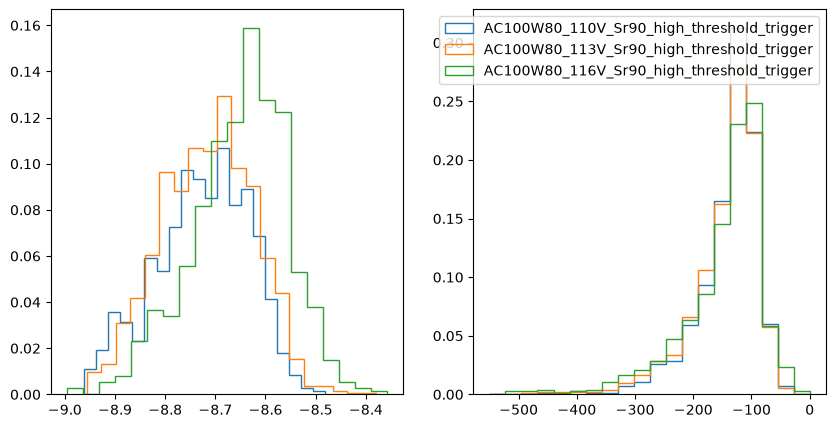

In [62]:
rows = 1
cols = 2
size = 5

fig, ax = plt.subplots(rows, cols, figsize = (cols*size, rows*size))

for key in amp.keys(): # "AC100W80_116V_Sr90_high_threshold_trigger"
    baseline_sel = (baseline_RMS[key][:,3] < 3)
    lead_strip = (amp[key][:,3]>amp[key][:,0]) & (amp[key][:,3]>amp[key][:,1]) & (amp[key][:,3]>amp[key][:,2]) & (amp[key][:,3]>amp[key][:,4]) & (amp[key][:,3]>amp[key][:,5]) & (amp[key][:,3]>amp[key][:,6])
    timestamp_sel = (timestamps[key][:,3]<-8)
    # timestamp_sel = (timestamps[key][:,3]<-8) & (timestamps[key][:,3]>-9)
    
    cuts = baseline_sel & lead_strip & timestamp_sel
    
    variable = timestamps[key][:,3][cuts]
    mean_timestamp = np.mean(variable)
    # print("Mean timestamp: ", np.mean(variable), " [ns]")
    print("Propagation time: ", max(variable) - min(variable), " [ns]")
    weights = np.ones(len(variable)) / len(variable)
    ax[0].hist(variable, bins = 20, histtype = "step", weights = weights, label = key)

    variable = risetime[key][:,3][cuts]
    mean_risetime = np.mean(variable)
    # print("Mean timestamp: ", np.mean(variable), " [ns]")
    print("Risetime range: ", max(variable) - min(variable), " [ns]")
    weights = np.ones(len(variable)) / len(variable)
    ax[1].hist(variable, bins = 20, histtype = "step", weights = weights, label = key, range = (-550, 0))

plt.legend()
plt.show()

0.5


/var/folders/rm/fk9q9bcs3t5_x29ybf88ljkh0000j6/T/ipykernel_9071/3556339406.py:46: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


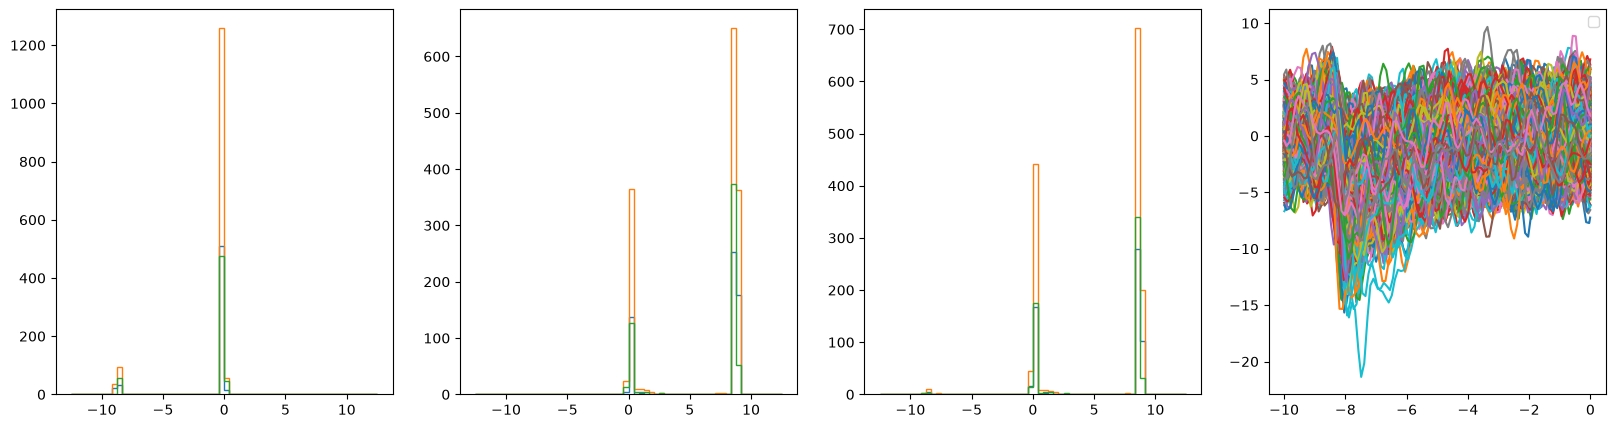

0.5144444444444445


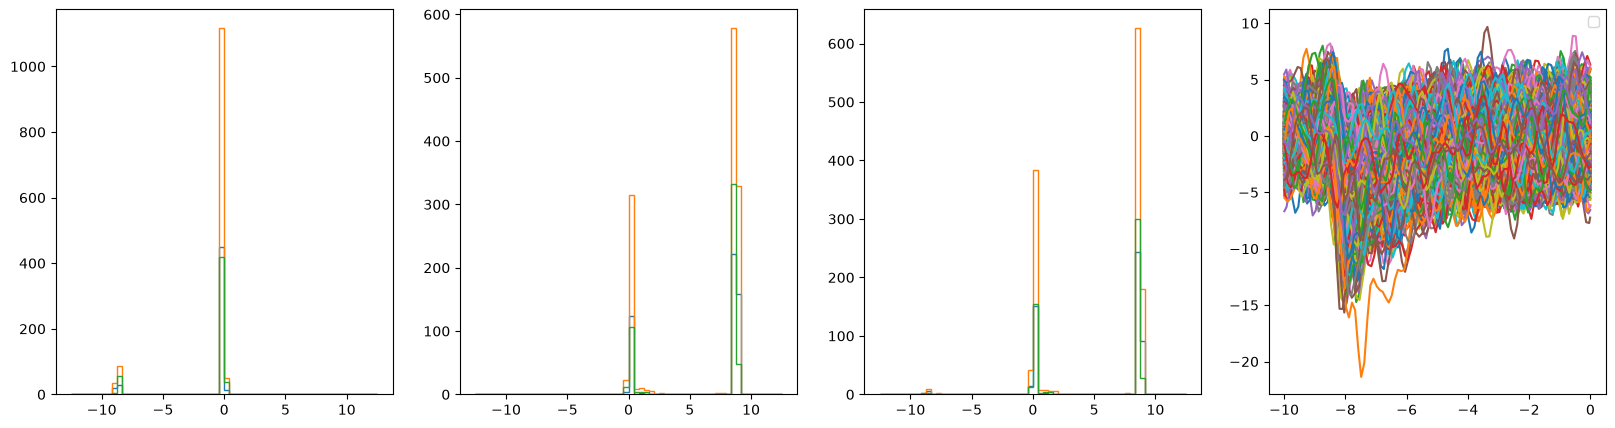

0.5288888888888889


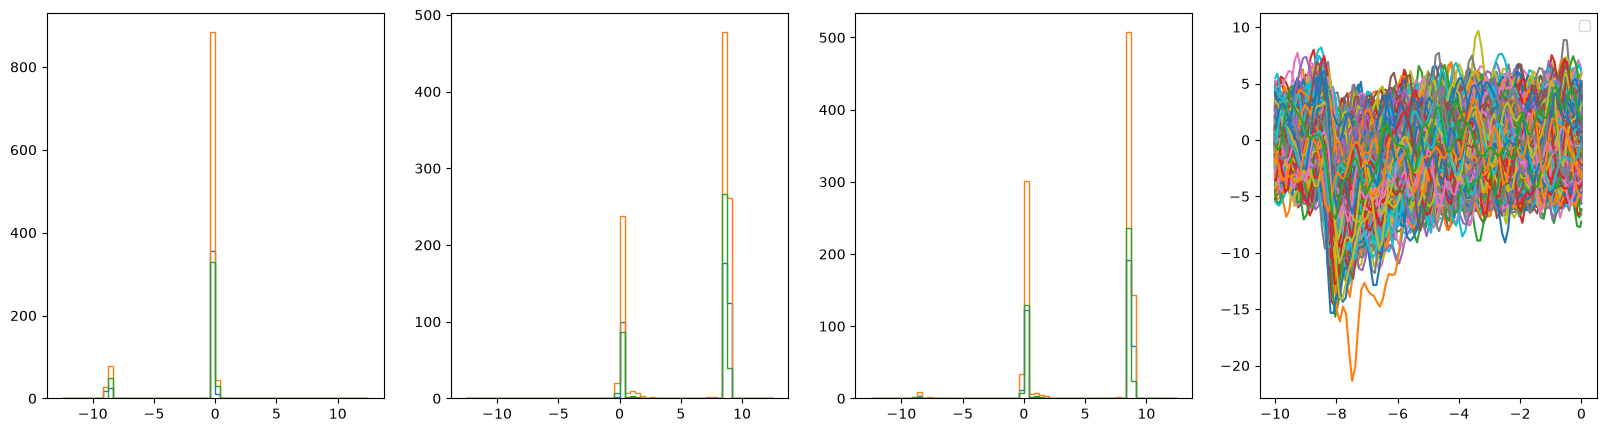

0.5433333333333333


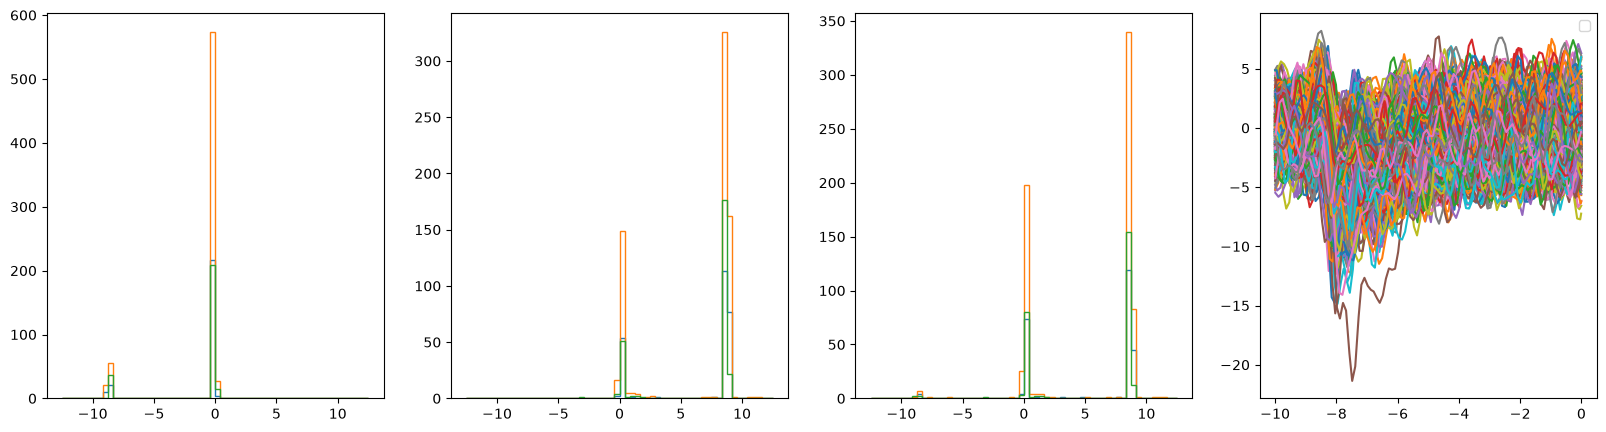

0.5577777777777778


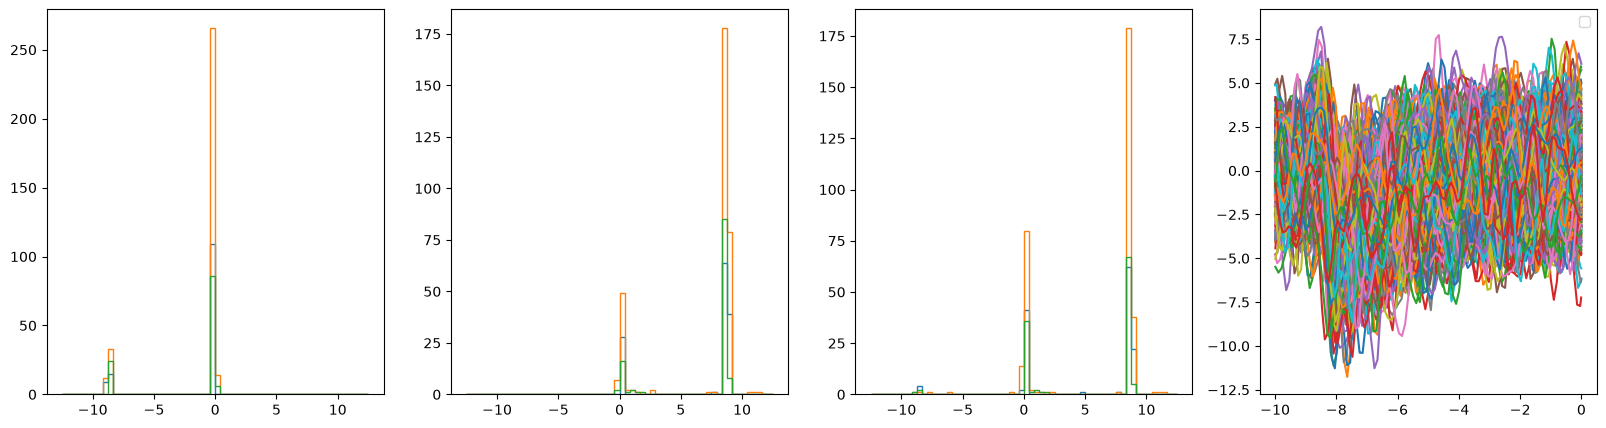

0.5722222222222222


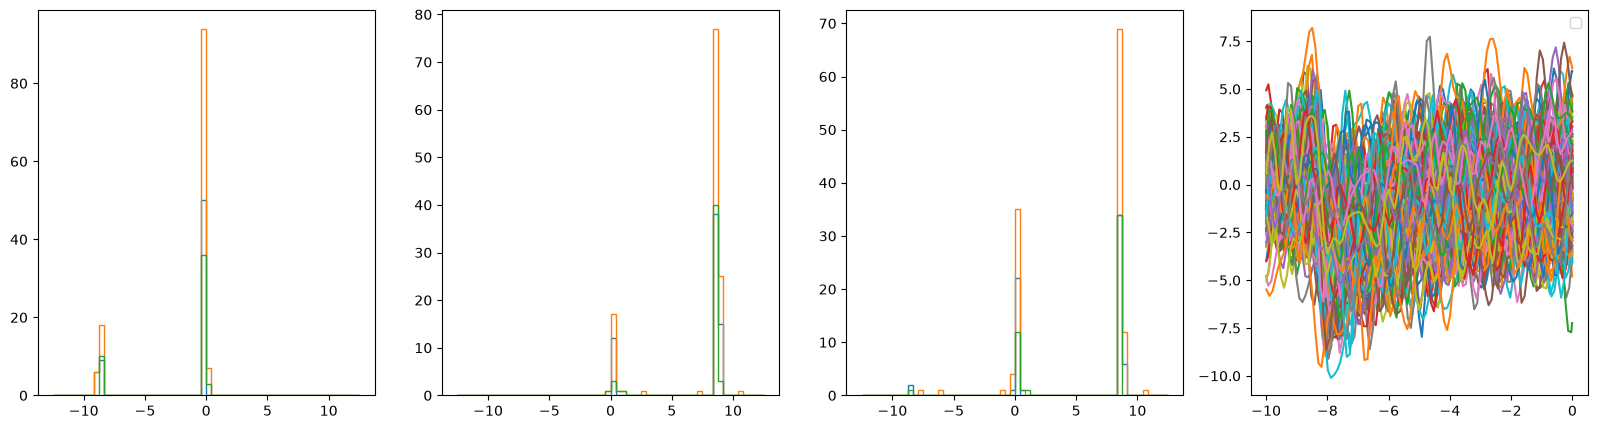

0.5866666666666667


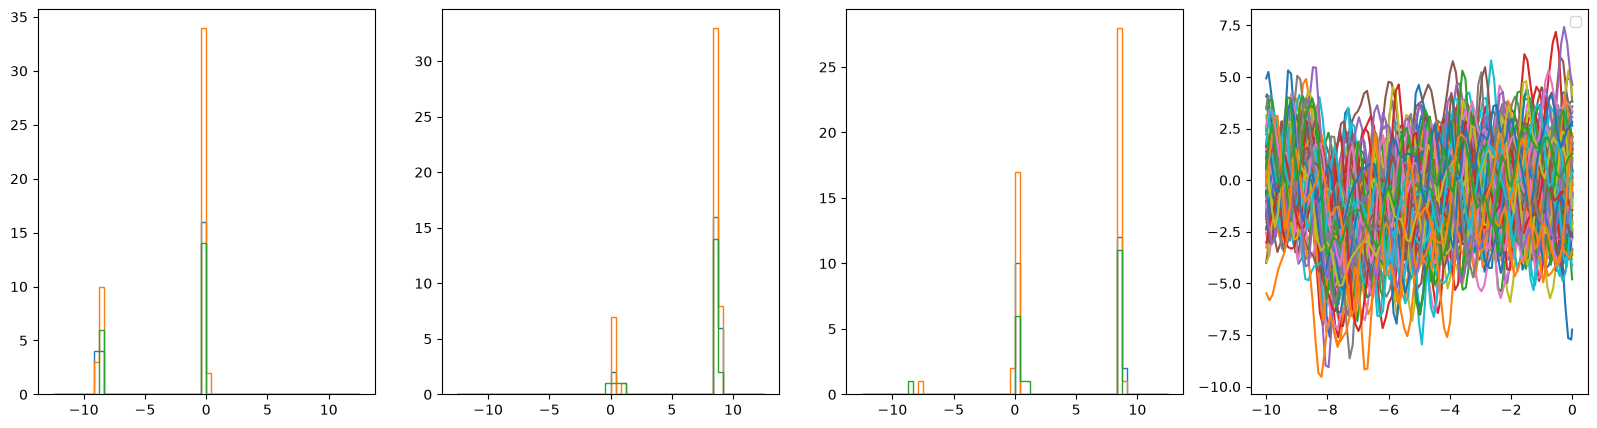

0.6011111111111112


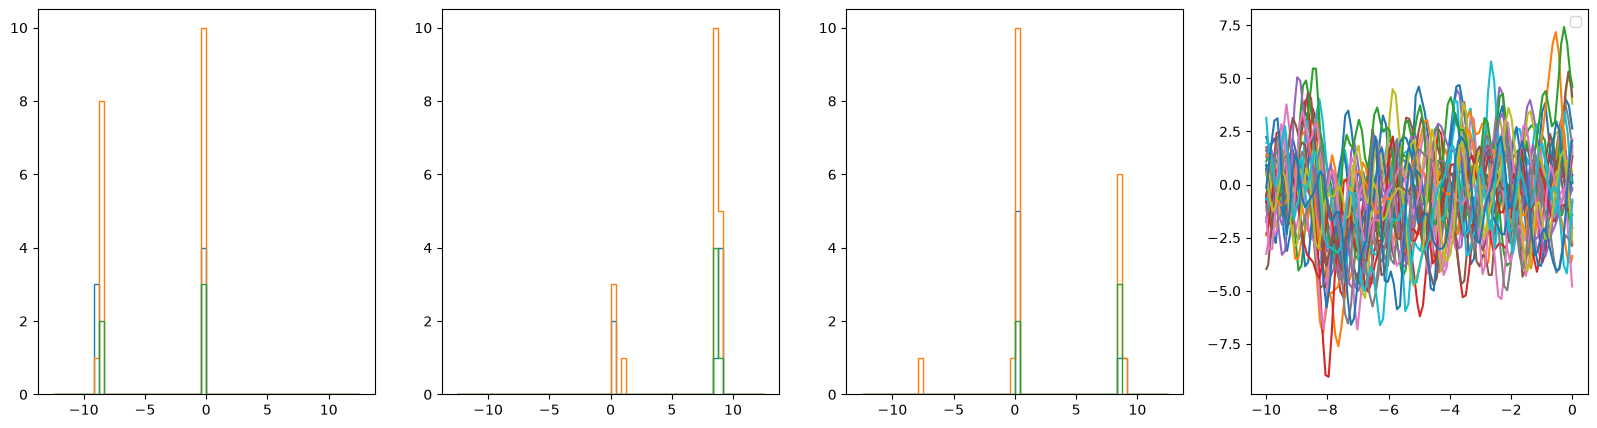

0.6155555555555555


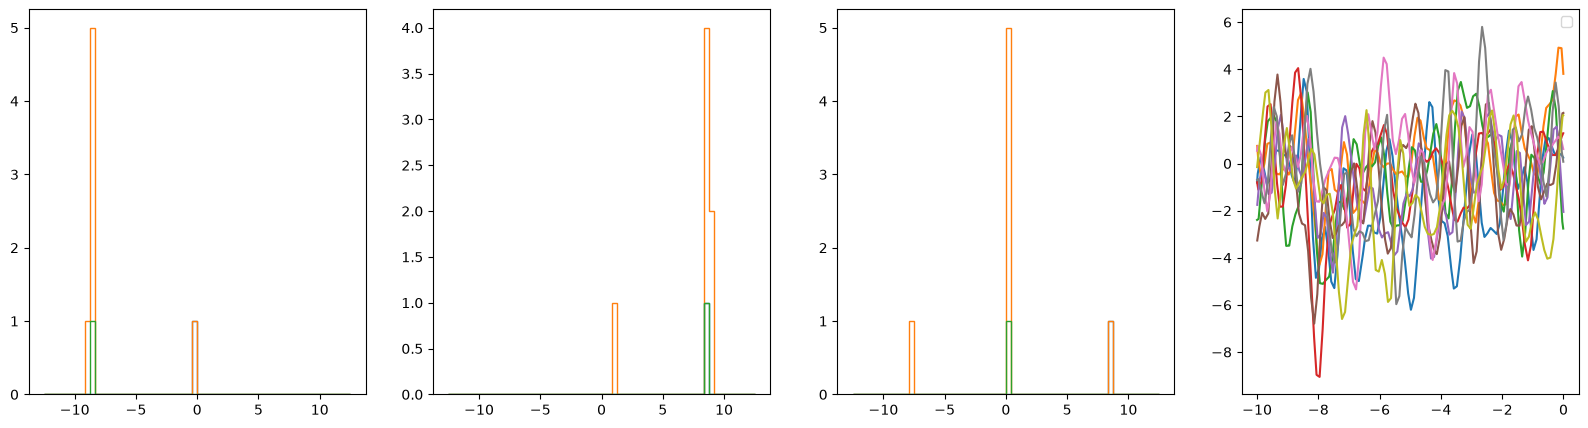

0.63


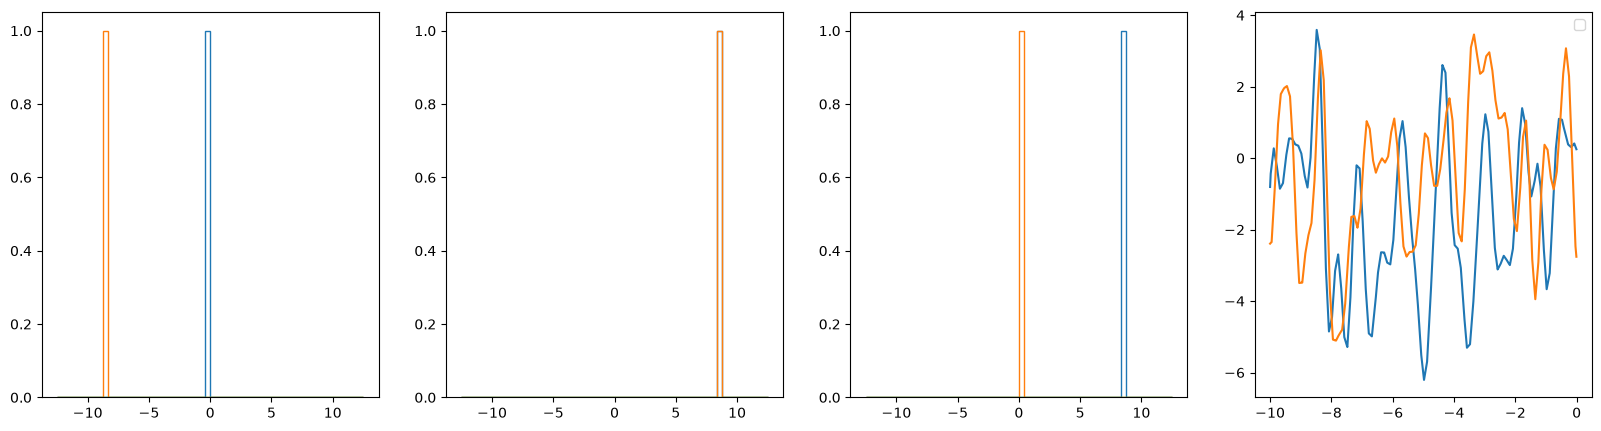

In [66]:
for frac in np.linspace(0.5, 0.63, 10):
    rows = 1
    cols = 4
    size = 5
    nbins = 60
    
    fig, ax = plt.subplots(rows, cols, figsize = (cols*size, rows*size))
    
    range_general = (-12.5, 12.5)
    print(frac)
    for key in amp.keys(): # "AC100W80_116V_Sr90_high_threshold_trigger"
        baseline_sel = (baseline_RMS[key][:,3] < 3)
        lead_strip = (amp[key][:,3]>amp[key][:,0]) & (amp[key][:,3]>amp[key][:,1]) & (amp[key][:,3]>amp[key][:,2]) & (amp[key][:,3]>amp[key][:,4]) & (amp[key][:,3]>amp[key][:,5]) & (amp[key][:,3]>amp[key][:,6])
        timestamp_sel = (timestamps[key][:,3]<-8)
        amp_fraction = (amp[key][:,3]>(amp[key][:,2]+amp[key][:,3]+amp[key][:,4])*frac)
        # timestamp_sel = (timestamps[key][:,3]<-8) & (timestamps[key][:,3]>-9)
        
        cuts = baseline_sel & lead_strip & timestamp_sel & amp_fraction
        
        central_strip = timestamps[key][:,3][cuts]
        edge_strip_1 = timestamps[key][:,4][cuts]
        edge_strip_2 = timestamps[key][:,5][cuts]
    
        variable = central_strip - edge_strip_1
        # print("Mean timestamp: ", np.mean(variable), " [ns]")
        # print("Propagation time: ", max(variable) - min(variable), " [ns]")
        weights = np.ones(len(variable)) # / len(variable)
        ax[0].hist(variable, bins = nbins, histtype = "step", weights = weights, label = key, range = range_general)
    
        variable = edge_strip_2 - central_strip
        # print("Mean timestamp: ", np.mean(variable), " [ns]")
        # print("Propagation time: ", max(variable) - min(variable), " [ns]")
        weights = np.ones(len(variable)) # / len(variable)
        ax[1].hist(variable, bins = nbins, histtype = "step", weights = weights, label = key, range = range_general)
    
        variable = edge_strip_2 - edge_strip_1
        # print("Mean timestamp: ", np.mean(variable), " [ns]")
        # print("Propagation time: ", max(variable) - min(variable), " [ns]")
        weights = np.ones(len(variable)) # / len(variable)
        ax[2].hist(variable, bins = nbins, histtype = "step", weights = weights, label = key, range = range_general)

        for i in range(len(channel[key][cuts])):
            range_sel = (time[key][cuts][i][0]>-10) & (time[key][cuts][i][0]<0)
            ax[3].plot(time[key][cuts][i][0][range_sel], channel[key][cuts][i][0][range_sel])
    
    plt.legend()
    plt.show()

In [ ]:
for key in amp.keys(): # "AC100W80_116V_Sr90_high_threshold_trigger"
    baseline_sel = (baseline_RMS[key][:,3] < 3)
    lead_strip = (amp[key][:,3]>amp[key][:,0]) & (amp[key][:,3]>amp[key][:,1]) & (amp[key][:,3]>amp[key][:,2]) & (amp[key][:,3]>amp[key][:,4]) & (amp[key][:,3]>amp[key][:,5]) & (amp[key][:,3]>amp[key][:,6])
    timestamp_sel = (timestamps[key][:,3]<-7)
    timestamp_sel = (timestamps[key][:,3]<-8) & (timestamps[key][:,3]>-9)
    
    cuts = baseline_sel & lead_strip & timestamp_sel
    
    variable = timestamps[key][:,3][cuts]
    print("Mean timestamp: ", np.mean(variable), " [ns]")
    print("Propagation time: ", max(variable) - min(variable), " [ns]")
    weights = np.ones(len(variable)) / len(variable)
    plt.hist(variable, bins = 20, histtype = "step", weights = weights, label = key)

plt.legend()
plt.show()

In [71]:
key = "AC100W80_110V_Sr90_high_threshold_trigger"

strip_mask = [True,False,True,True,True,True,True,False]

toa = []
amplitude_ratio = []
delta_toa = []
delta_wt_toa = []
weight_toa = []

for i in range(len(amp[key])):
    if baseline_RMS[key][i][2] > 3: continue
    # if ( 
    #     not ((amp[key][i][3]>amp[key][i][0]) &
    #     (amp[key][i][3]>amp[key][i][1]) & 
    #     (amp[key][i][3]>amp[key][i][2]) & 
    #     (amp[key][i][3]>amp[key][i][4]) &
    #     (amp[key][i][3]>amp[key][i][5]) & 
    #     (amp[key][i][3]>amp[key][i][6]))
    # ): continue

    if ( 
        not ((amp[key][i][2]>amp[key][i][0]) &
        (amp[key][i][2]>amp[key][i][1]) & 
        (amp[key][i][2]>amp[key][i][3]) & 
        (amp[key][i][2]>amp[key][i][4]) &
        (amp[key][i][2]>amp[key][i][5]) & 
        (amp[key][i][2]>amp[key][i][6])
        )
    ): continue

    sort_index = np.argsort(amp[key][:, strip_mask][i])
    lead_strips = sort_index[-2::]
    
    lead_amps = amp       [key][:, strip_mask][i][lead_strips] 
    lead_toas = timestamps[key][:, strip_mask][i][lead_strips]
    
    toa         .append(lead_toas[0])
    delta_toa   .append(lead_toas[0] - lead_toas[1])
    weight_toa  .append( (lead_toas[0] * lead_amps[0]**2 + lead_toas[1] * lead_amps[1]**2) / (lead_amps[0]**2 + lead_amps[1]**2) )
    delta_wt_toa.append(lead_toas[0] - weight_toa[-1])

delta_toa    = np.array(delta_toa)
weight_toa   = np.array(weight_toa)
delta_wt_toa = np.array(delta_wt_toa)

# print(delta_toa)
# print(lead_strips)
# print(lead_amps)
# if (np.abs(lead_strips[0]-lead_strips[1])>1): print(np.abs(lead_strips[0]-lead_strips[1]))


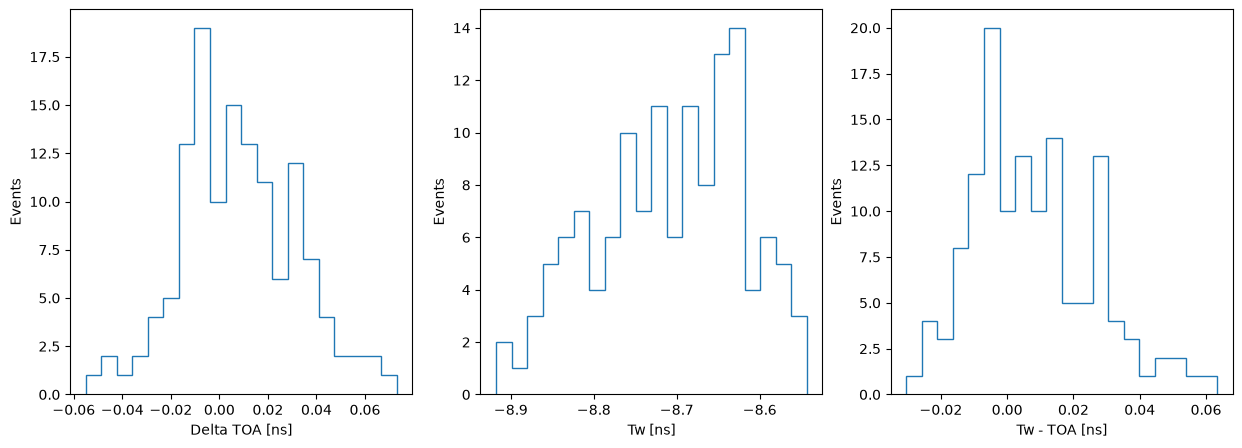

In [72]:
rows = 1
cols = 3
size = 5
nbins = 20

fig, ax = plt.subplots(rows, cols, figsize = (cols*size, rows*size))

sel = weight_toa < 0

ax[0].hist(delta_toa[sel], histtype="step", bins = nbins)
ax[0].set_xlabel("Delta TOA [ns]")
ax[0].set_ylabel("Events")

ax[1].hist(weight_toa[sel], histtype="step", bins = nbins)
ax[1].set_xlabel("Tw [ns]")
ax[1].set_ylabel("Events")

ax[2].hist(delta_wt_toa[sel], histtype="step", bins = nbins)
ax[2].set_xlabel("Tw - TOA [ns]")
ax[2].set_ylabel("Events")

plt.show()

In [ ]:
for key in amp.keys(): # "AC100W80_116V_Sr90_high_threshold_trigger"
    baseline_sel = (baseline_RMS[key][:,3] < 3)
    lead_strip = (amp[key][:,3]>amp[key][:,0]) & (amp[key][:,3]>amp[key][:,1]) & (amp[key][:,3]>amp[key][:,2]) & (amp[key][:,3]>amp[key][:,4]) & (amp[key][:,3]>amp[key][:,5]) & (amp[key][:,3]>amp[key][:,6])
    timestamp_sel = (timestamps[key][:,3]<-7)
    timestamp_sel = (timestamps[key][:,3]<-8) & (timestamps[key][:,3]>-9)
    
    cuts = baseline_sel & lead_strip & timestamp_sel
    
    variable = timestamps[key][:,3][cuts]
    print("Mean timestamp: ", np.mean(variable), " [ns]")
    print("Propagation time: ", max(variable) - min(variable), " [ns]")
    weights = np.ones(len(variable)) / len(variable)
    plt.hist(variable, bins = 20, histtype = "step", weights = weights, label = key)

plt.legend()
plt.show()